# plot flux from river cell

Contact: Chao Zeng, chao.zeng@pnnl.gov

In [1]:
import numpy as np
import h5py as h5
import glob
import pickle
import scipy

import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from datetime import datetime, timedelta

from shapely.geometry.polygon import Polygon
# import statsmodels.api as sm
# import statsmodels.formula.api as smf
from numpy.polynomial.polynomial import polyfit
from scipy import stats
from tqdm.notebook import tqdm

import geopandas as gpd
from mpl_toolkits.axes_grid1.inset_locator import zoomed_inset_axes, mark_inset

In [2]:
def batch_time_to_delta(origin, x, time_format):
    y = []
    for ix in x:
        temp_y = abs(datetime.strptime(
            ix, time_format) - origin).total_seconds()
        y.append(temp_y)
    y = np.asarray(y)
    return(y)

def batch_delta_to_time(origin, x, time_format, delta_format):
    y = []
    for ix in x:
        if delta_format == "hours":
            temp_y = origin + timedelta(hours=ix)
        elif delta_format == "days":
            temp_y = origin + timedelta(days=ix)
        elif delta_format == "minutes":
            temp_y = origin + timedelta(minutes=ix)
        elif delta_format == "weeks":
            temp_y = origin + timedelta(weeks=ix)
        elif delta_format == "seconds":
            temp_y = origin + timedelta(seconds=ix)
        elif delta_format == "microseconds":
            temp_y = origin + timedelta(microseconds=ix)
        elif delta_format == "milliseconds":
            temp_y = origin + timedelta(milliseconds=ix)
        else:
            print("Sorry, this naive program only solve single time unit")
        y.append(temp_y.strftime(time_format))
    y = np.asarray(y)
    return(y)

In [3]:
date_origin = datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")

**read mass1 coordinates**

In [4]:
fname_mass1_coord = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/mass1/Mass1_datum_shift.csv'

mass1_coord_all = pd.read_csv(fname_mass1_coord, index_col='quadrant')

mass1_coord = mass1_coord_all.loc[35:, :].copy()

mass1_coord['distance'] = mass1_coord['riverkm'] - mass1_coord.loc[360, 'riverkm']

**read materail.h5 file**

In [5]:
fname_material_h5 = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID-river.h5'

material_h5 = h5.File(fname_material_h5, "r")
#print(material_h5['Regions'].keys())

# Extract keys that start with 'Mass1_'
mass1_keys = [key for key in material_h5['Regions'].keys() if key.startswith('Mass1_')]

# Sort keys numerically based on the number after 'Mass1_'
sorted_mass1_keys = sorted(mass1_keys, key=lambda x: int(x.split('_')[1]))

top_layer = material_h5['Regions']['Top']['Vertex Ids'][:,1:4]  #(three vertex ids for top layer faces)

river_cell_ids = []
for isection in sorted_mass1_keys:
    river_face = material_h5['Regions'][isection]['Vertex Ids'][:,1:4]    # (three vertex ids for river faces)
    for vertex in river_face:
        cell_ids = np.array(np.where((top_layer==vertex).all(axis=1))).ravel()
        river_cell_ids.extend(cell_ids)                

In [6]:
print(np.shape(river_cell_ids))
print(river_cell_ids[:10])

(19476,)
[25195, 25300, 25301, 25305, 25314, 25321, 25322, 25323, 25324, 25329]


**visualize the cell shape nad vetex order**

example cell ids=[17567], vertices=[19513 19519 19512 19516 19522 19515]


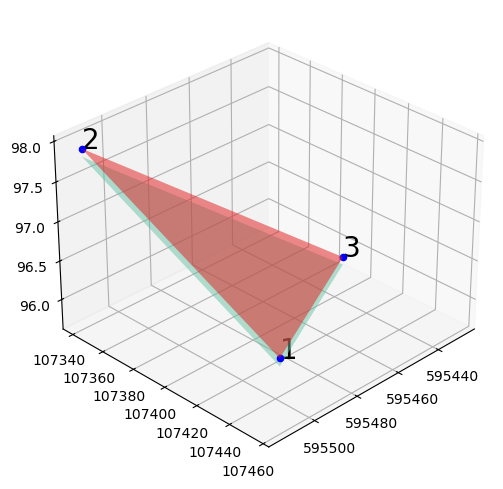

In [7]:
from matplotlib import cm

all_cell = material_h5['Domain']['Cells'][:,1::]
all_vertices_coord = material_h5['Domain']['Vertices']

spec_cell = all_cell[cell_ids]-1
spec_cell = spec_cell.ravel()
print(f"example cell ids={cell_ids}, vertices={spec_cell}")
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(111, projection='3d')

for i in range(len(spec_cell[:3])):    # only print the first three points
    ax.scatter(all_vertices_coord[spec_cell[i], 0], all_vertices_coord[spec_cell[i], 1], all_vertices_coord[spec_cell[i], 2],
               c='b', marker='o')
    ax.text(all_vertices_coord[spec_cell[i], 0], all_vertices_coord[spec_cell[i], 1], all_vertices_coord[spec_cell[i], 2], 
            '%s' % str(i + 1), size=20, zorder=1, color='k') 

    # Plot trisurf on the first three points
spec_cell[:3].sort()
ax.plot_trisurf(all_vertices_coord[spec_cell[:3], 0], all_vertices_coord[spec_cell[:3], 1], all_vertices_coord[spec_cell[:3], 2], 
                cmap=cm.Set1, linewidth=1, alpha=0.5)
spec_cell[3:].sort()

# Plot trisurf on the remaining three points
ax.plot_trisurf(all_vertices_coord[spec_cell[3:], 0], all_vertices_coord[spec_cell[3:], 1], all_vertices_coord[spec_cell[3:], 2], 
                cmap=cm.Set2, linewidth=1, alpha=0.5)

# adjust the rotation
ax.view_init(elev=30, azim=45)    # change elev and azim to rotate the plot

# Display the plot
plt.show()

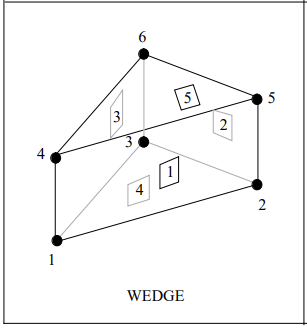
The vertices ordering for wedge unstructured mesh is shown from pflotran manual. The river top face is face 4th. 

**import boundary face flux**

In [8]:
#fname_pflotran_h5 = '/pscratch/sd/z/zc727/model_iso_perm/HFR-iso-perm.h5'                                         # isotropic model
#fname_pflotran_h5 = '/pscratch/sd/z/zc727/model_aniso_perm_except_basalt/perm_all_except_basalt.h5'              # anisotropic permeability model(except basalt)
fname_pflotran_h5 = '/pscratch/sd/z/zc727/model_aniso_perm_only_alluvium/perm_only_alluvium.h5'                  # anisotropic permeability model(only alluvium)

h5file = h5.File(fname_pflotran_h5, 'r')
groups = list(h5file.keys())
time_index = [i for i, s in enumerate(groups) if "Time" in s]
times = [groups[i].split(' ')[-2] for i in time_index]
times = list(map(float, times))
real_time = batch_delta_to_time(date_origin, times, "%Y-%m-%d %H:%M:%S", "hours")
real_time = [datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in real_time]

In [9]:
# Function to calculate the normal of a triangle
def calculate_normal(A, B, C):
    # Calculate two vectors from the triangle's vertices
    AB = B - A
    AC = C - A
    # Compute the initial normal using the cross product
    normal = np.cross(AB, AC)
    # Normalize the initial normal
    normal = normal / np.linalg.norm(normal)
    # Ensure the normal points in the positive z direction
    if normal[2] < 0:
        normal = -normal
    return normal

# Function to project a vector onto another
def project_vector_to_normal(v, normal):
    # Project vector v onto normal
    return np.dot(v, normal)

**import river geometry**

In [10]:
from shapely.geometry.polygon import Polygon

fname_river_geo = '/global/cfs/cdirs/m1800/pin/Reach_scale_model/data/river_geometry_manual_v2.csv'

river_geo = pd.read_csv(fname_river_geo)

river_geo['x'] = river_geo['x']/1000          # convert to km
river_geo['y'] = river_geo['y']/1000          # convert to km

polygon = Polygon(river_geo.loc[:, ["x", "y"]].values)
river_x,river_y = polygon.exterior.xy

**calcuate the river face and flux dataset**

In [11]:
t_idx = 100
print(f"the datetime is:{real_time[t_idx]}")
# get the flux (m/h)
idx = groups[t_idx]
x_darcy = h5file[idx]['Liquid X-Velocity at cell face [m_per_h]']
y_darcy = h5file[idx]['Liquid Y-Velocity at cell face [m_per_h]']
z_darcy = h5file[idx]['Liquid Z-Velocity at cell face [m_per_h]']

xy_flux = np.zeros(np.size(river_cell_ids))
xy_coord = np.zeros([len(river_cell_ids),3, 2])
for idx, cell_id in enumerate(river_cell_ids):
    cell_vertices = all_cell[cell_id, 1:4]
    vertices_coord = all_vertices_coord[sorted(cell_vertices-1),:]
    xy_coord[idx,:,:] = vertices_coord[:,:-1]
    
    normal = calculate_normal(vertices_coord[0], vertices_coord[1], vertices_coord[2])
    
    # retrieve flux from pflotran output:
    v_x = np.array([x_darcy[cell_id, 4], 0, 0]) 
    v_y = np.array([0, y_darcy[cell_id, 4], 0])
    v_z = np.array([0, 0, z_darcy[cell_id, 4]])
        
    # calculate the surface normal to river face
    # normal: along positive-z direction
    exchange_flux = project_vector_to_normal(v_x, normal) + project_vector_to_normal(v_y, normal) + project_vector_to_normal(v_z, normal)
    xy_flux[idx] = exchange_flux*24   # convert to m/d    

the datetime is:2008-05-15 00:00:00


**plot the rive face triangle**

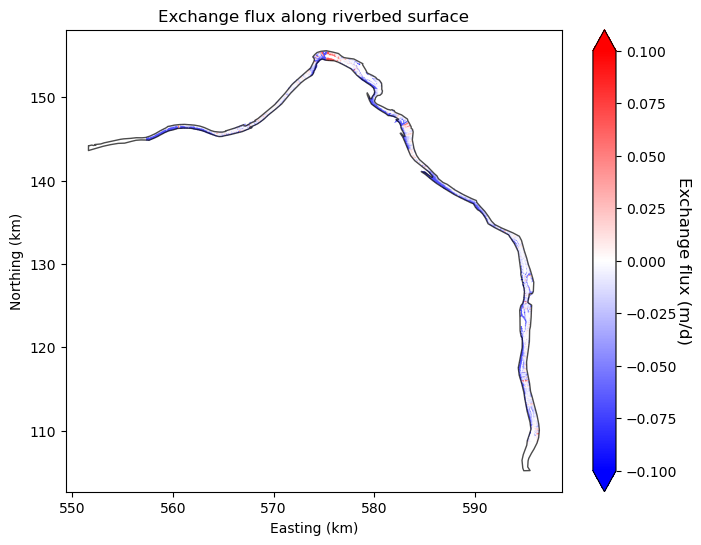

In [12]:
import matplotlib.patches as patches
from matplotlib.collections import PatchCollection

fig, ax = plt.subplots(figsize=(8,6))
patches_list = []
# plot river geometry
ax.plot(river_x, river_y, color='black', alpha=0.7, linewidth=1, solid_capstyle='round', zorder=2) 
# loop over each triangle
for i in range(xy_coord.shape[0]):
    # Get vertices for the current triangle
    triangle_vertices = xy_coord[i]/1000        # convert to km
    # create a polygon for the current set of vertices
    polygon = patches.Polygon(triangle_vertices, closed=True)
    patches_list.append(polygon)
# Create a PatchCollection
patch_collection = PatchCollection(patches_list, cmap=plt.cm.bwr, edgecolor='none')
patch_collection.set_array(xy_flux)
ax.add_collection(patch_collection)
# Set specific vmin and vmax
vmin, vmax = -0.1, 0.1
patch_collection.set_clim(vmin=vmin, vmax=vmax)
# Add a colorbar
cbar = plt.colorbar(patch_collection, ax=ax, orientation='vertical',extend='both')
cbar.ax.set_ylabel("Exchange flux (m/d)", rotation=270, labelpad=10, fontsize=12)

plt.title("Exchange flux along riverbed surface")
plt.xlabel("Easting (km)")
plt.ylabel("Northing (km)")
plt.show()

**import river stage info**

In [13]:
import re
import datetime
import matplotlib.dates as mdates

In [14]:
def natural_sort(l): 
    convert = lambda text: int(text) if text.isdigit() else text.lower() 
    alphanum_key = lambda key: [ convert(c) for c in re.split('([0-9]+)', key) ] 
    return sorted(l, key = alphanum_key)  

In [15]:
fname_river_bc = '/global/homes/z/zc727/HFR/data/stage_2007-2019/'
datum_files = glob.glob(fname_river_bc + "Datum*.txt")                        # 1h interval
datum_files = natural_sort(datum_files)

In [16]:
river_north_datum = pd.read_table(datum_files[0], sep=' ', header=None, names=['time', 'x', 'y', 'wl'])
river_middle_datum = pd.read_table(datum_files[(len(datum_files)-1)//2], sep=' ', header=None, names=['time', 'x', 'y', 'wl'])
river_south_datum = pd.read_table(datum_files[-1], sep=' ', header=None, names=['time', 'x', 'y', 'wl'])

date_origin = datetime.datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")
river_north_datum['time'] = batch_delta_to_time(date_origin, river_north_datum['time'], "%Y-%m-%d %H:%M:%S", "seconds")
river_middle_datum['time'] = batch_delta_to_time(date_origin, river_middle_datum['time'], "%Y-%m-%d %H:%M:%S", "seconds")
river_south_datum['time'] = batch_delta_to_time(date_origin, river_south_datum['time'], "%Y-%m-%d %H:%M:%S", "seconds")

In [17]:
river_north_datum['time'] = river_north_datum['time'].apply(pd.to_datetime)
river_middle_datum['time'] = river_middle_datum['time'].apply(pd.to_datetime)
river_south_datum['time'] = river_south_datum['time'].apply(pd.to_datetime)

In [18]:
start_time = datetime.datetime.strptime("2007-01-01 00:00:00", "%Y-%m-%d %H:%M:%S")

time_ticks = [
    "2011-01-01 00:00:00",
    "2012-01-01 00:00:00",
    "2013-01-01 00:00:00",
    "2014-01-01 00:00:00",
    "2015-01-01 00:00:00",
    "2016-01-01 00:00:00"]
time_ticks = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in time_ticks]

# ONLY select two time slot: one min and one max
selected_ticks = [                    
    "2011-06-04 00:00:00",
    "2011-09-12 00:00:00"
    ]
selected_ticks = [datetime.datetime.strptime(x, "%Y-%m-%d %H:%M:%S") for x in selected_ticks]

**calculate the river face and flux**

In [19]:
print(selected_ticks[0])
print(real_time[343])

# Find the index of the specified datetime
indices=[]
for date in selected_ticks:
    index = real_time.index(date)
    indices.append(index)
    
print(indices)

2011-06-04 00:00:00
2011-09-12 00:00:00
[323, 343]


In [20]:
xy_flux = np.zeros([len(indices),len(river_cell_ids)])
xy_coord = np.zeros([len(river_cell_ids),3, 2])
xyz_centroid = np.zeros([len(river_cell_ids),3])

for i, t_idx in enumerate(indices):
    print(f"the datetime is:{real_time[t_idx]}")
    # get the flux (m/h)
    idx = groups[t_idx]
    x_darcy = h5file[idx]['Liquid X-Velocity at cell face [m_per_h]']
    y_darcy = h5file[idx]['Liquid Y-Velocity at cell face [m_per_h]']
    z_darcy = h5file[idx]['Liquid Z-Velocity at cell face [m_per_h]']

    for idx, cell_id in enumerate(river_cell_ids):
        cell_vertices = all_cell[cell_id, 1:4]
        vertices_coord = all_vertices_coord[sorted(cell_vertices-1),:]
        xy_coord[idx,:,:] = vertices_coord[:,:-1]
        xyz_centroid[idx,:] = [vertices_coord[:,0].mean(),vertices_coord[:,1].mean(),vertices_coord[:,2].mean()]
        
        normal = calculate_normal(vertices_coord[0], vertices_coord[1], vertices_coord[2])
    
        # retrieve flux from pflotran output:
        v_x = np.array([x_darcy[cell_id, 4], 0, 0]) 
        v_y = np.array([0, y_darcy[cell_id, 4], 0])
        v_z = np.array([0, 0, z_darcy[cell_id, 4]])
        
        # calculate the surface normal to river face
        # normal: along positive-z direction
        exchange_flux = project_vector_to_normal(v_x, normal) + project_vector_to_normal(v_y, normal) + project_vector_to_normal(v_z, normal)
        xy_flux[i,idx] = exchange_flux*24   # convert to m/d 

the datetime is:2011-06-04 00:00:00
the datetime is:2011-09-12 00:00:00


In [21]:
# output the data for further process
import os

# Extract the base name without extension
base_name = os.path.splitext(os.path.basename(fname_pflotran_h5))[0]

# Construct the output CSV file name
output_csv_name = f'/global/homes/z/zc727/HFR/output/exchange_flux_contour/{base_name}.csv'

# Transpose xy_flux to align correctly with cell_number as rows
xy_flux_transposed = xy_flux.T  # Now shape (cell_number, 2)

# Combine the data into a single DataFrame
combined_data = np.hstack((xyz_centroid, xy_flux_transposed))  # Shape (cell_number, 5)

# Column names for the DataFrame
column_names = ['Centroid_X', 'Centroid_Y', 'Centroid_Z', 'Flux@time_1', 'Flux@time_2']

# Create a DataFrame
df = pd.DataFrame(combined_data, columns=column_names)

# Save to CSV with the constructed name
df.to_csv(output_csv_name, index=False)

print(f"Data saved to {output_csv_name}")

Data saved to /global/homes/z/zc727/HFR/output/exchange_flux_contour/perm_only_alluvium.csv


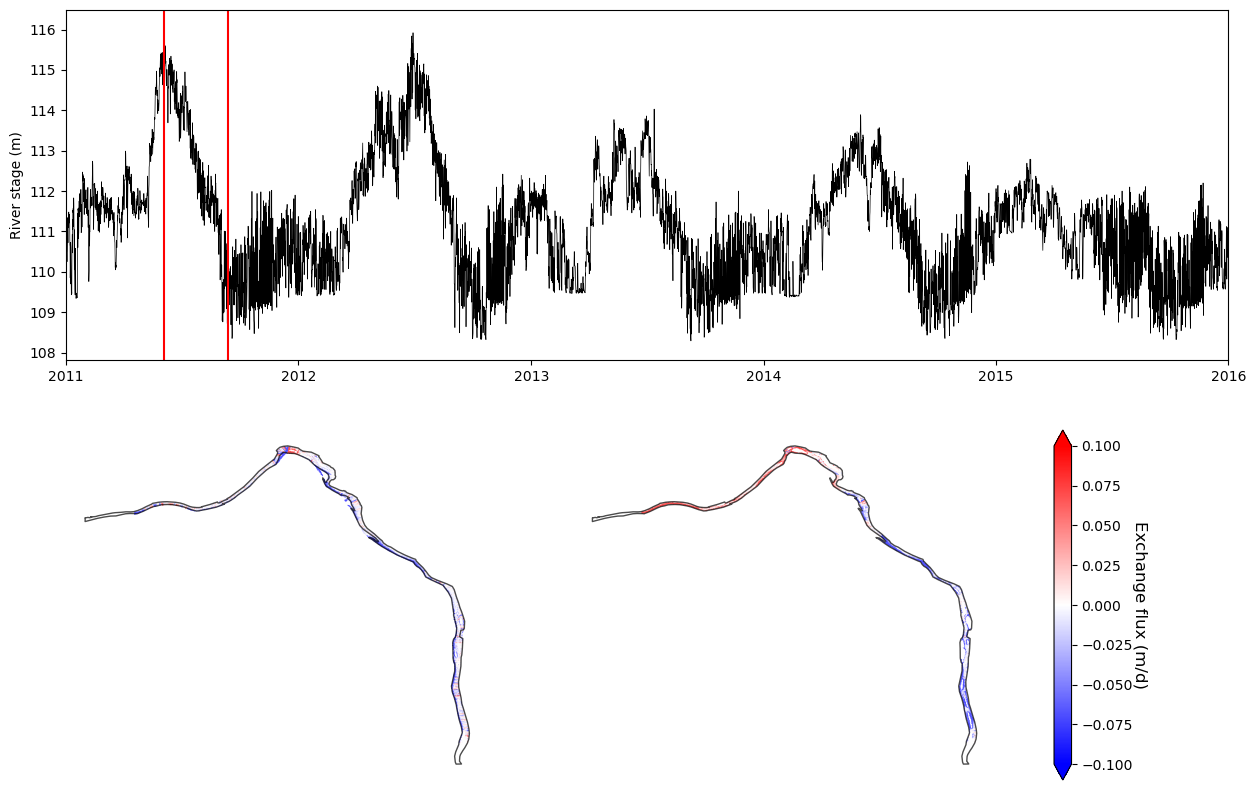

In [22]:
fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], width_ratios=[1, 1])

# Subplot 1: River stage data at the top
ax1 = fig.add_subplot(gs[0, :])  # Span across two columns
ax1.plot(river_middle_datum.loc[::6, 'time'], river_middle_datum.loc[::6, 'wl'], color='black', linewidth=0.5)

# Plot vertical lines for selected times
for itime in selected_ticks:
    ax1.axvline(itime, color='red', linestyle='-')

ax1.set_ylabel('River stage (m)')
ax1.set_xlabel('')
ax1.set_xticks(time_ticks)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.set_xlim([time_ticks[0], time_ticks[-1]])

# Subplot 2: Polygon on the left bottom
ax2 = fig.add_subplot(gs[1, 0])
patches_list = [patches.Polygon(xy_coord[i]/1000.0, closed=True) for i in range(xy_coord.shape[0])]
patch_collection2 = PatchCollection(patches_list, cmap=plt.cm.bwr, edgecolor='none')
patch_collection2.set_array(xy_flux[0])
patch_collection2.set_clim(vmin=-0.1, vmax=0.1)
ax2.plot(river_x, river_y, color='black', alpha=0.7, linewidth=1, solid_capstyle='round', zorder=2)
ax2.add_collection(patch_collection2)
ax2.axis('off')  # Hide axes

# Subplot 3: Polygon on the right bottom
ax3 = fig.add_subplot(gs[1, 1])
patch_collection3 = PatchCollection(patches_list, cmap=plt.cm.bwr, edgecolor='none')
patch_collection3.set_array(xy_flux[1])
patch_collection3.set_clim(vmin=-0.1, vmax=0.1)
ax3.plot(river_x, river_y, color='black', alpha=0.7, linewidth=1, solid_capstyle='round', zorder=2)
ax3.add_collection(patch_collection3)
ax3.axis('off')  # Hide axes

# Shared colorbar for polygon plots
cbar = fig.colorbar(patch_collection3, ax=[ax2, ax3], orientation='vertical', extend='both')
cbar.ax.set_ylabel("Exchange flux (m/d)", rotation=270, labelpad=10, fontsize=12)

#plt.suptitle("Exchange flux along riverbed surface")
plt.show()